<a href="https://colab.research.google.com/github/672023033-hub/Daily-Maximum-Temperature-Prediction-Using-LSTM-Larantuka/blob/main/Prediksi_Suhu_Larantuka.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Setup Visual
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (15, 8)

# Load Dataset
file_path = 'POWER_Point_Daily_20210101_20260131_008d34S_122d98E_LST.csv'
df = pd.read_csv(file_path, skiprows=14)

# Konversi Tanggal 2021 - 2026
df['Date'] = pd.to_datetime(df['YEAR'].astype(str) + df['DOY'].astype(str), format='%Y%j')
df = df.sort_values('Date').reset_index(drop=True)

# Fitur sesuai dataset baru (Target: T2M_MAX di Index 1 pada kolom asli, tapi kita pindahkan ke Index 0)
features = ['T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'T2M', 'RH2M', 'ALLSKY_SFC_SW_DWN']
dataset = df[features].values

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(dataset)

print(f"✅ Data 2021-2026 Terbaca Semua. Rentang: {df['Date'].min()} s/d {df['Date'].max()}")

✅ Data 2021-2026 Terbaca Semua. Rentang: 2021-01-01 00:00:00 s/d 2026-01-31 00:00:00


In [ ]:
WINDOW_SIZE = 60
X, y = [], []

for i in range(WINDOW_SIZE, len(scaled_data)):
    X.append(scaled_data[i-WINDOW_SIZE:i, :])
    y.append(scaled_data[i, 0]) # Target: T2M_MAX

X, y = np.array(X), np.array(y)
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = Sequential([
    LSTM(100, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(50),
    Dropout(0.2),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_test, y_test), verbose=1)

Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - loss: 0.0767 - val_loss: 0.0104
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - loss: 0.0138 - val_loss: 0.0102
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - loss: 0.0129 - val_loss: 0.0104
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 0.0126 - val_loss: 0.0120
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - loss: 0.0123 - val_loss: 0.0098
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - loss: 0.0113 - val_loss: 0.0095
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 0.0129 - val_loss: 0.0091
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - loss: 0.0110 - val_loss: 0.0092
Epoch 9/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 91ms/step - loss: 0.0115 - val_loss: 0.0092
Epoch 10/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - loss: 0.0109 - val_loss: 0.0089
Epoch 11/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - loss: 0.0118 - val_loss: 0.0099
Epoch 12/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - loss: 0.0113 - val_l

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step


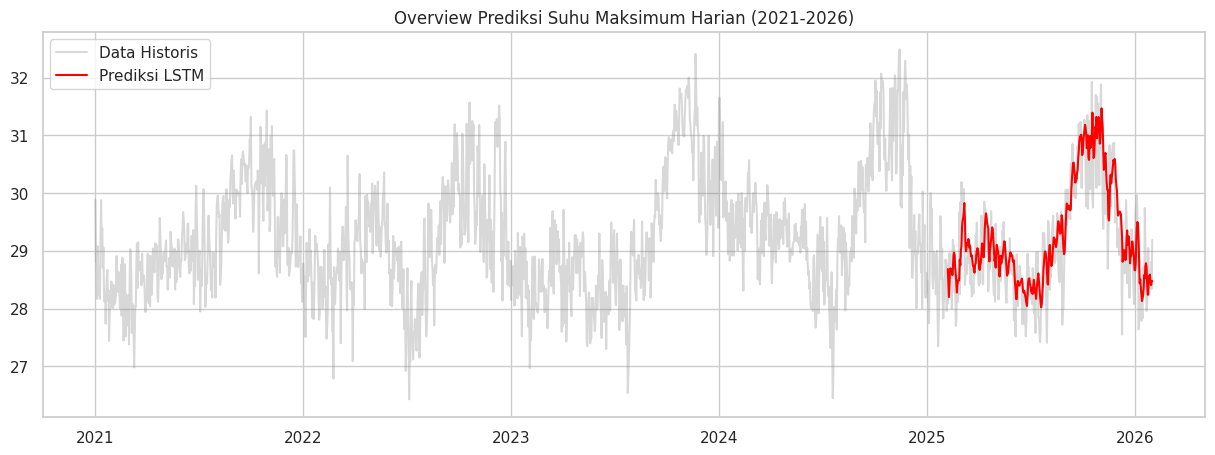

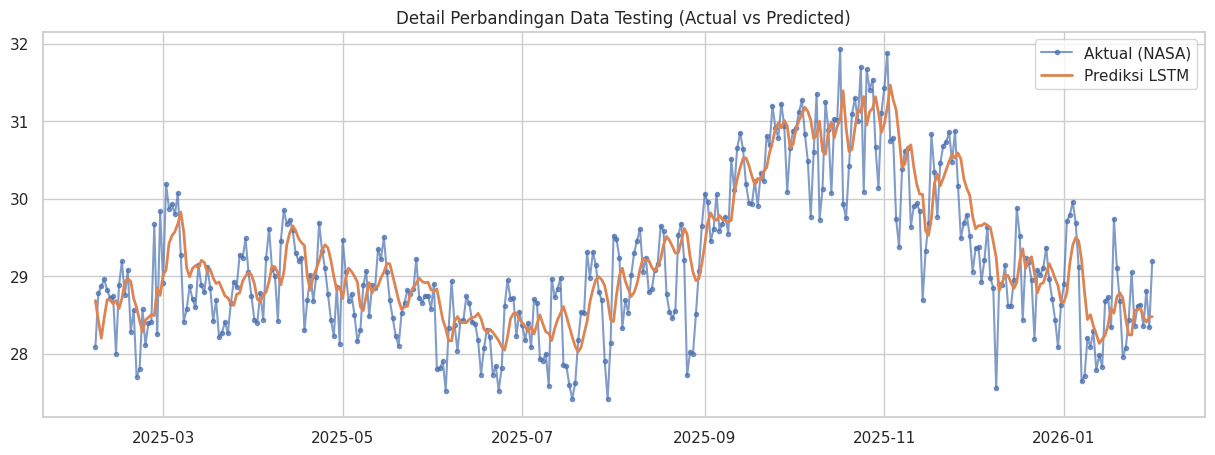

In [ ]:
# Prediksi
y_pred_scaled = model.predict(X_test)

def to_c(v):
    d = np.zeros((len(v), len(features)))
    d[:, 0] = v.flatten()
    return scaler.inverse_transform(d)[:, 0]

y_act = to_c(y_test)
y_pred = to_c(y_pred_scaled)
dates_test = df['Date'].iloc[-len(y_act):]

# Visualisasi 1: Overview Prediksi
plt.figure(figsize=(15, 5))
plt.plot(df['Date'], df['T2M_MAX'], color='gray', alpha=0.3, label='Data Historis')
plt.plot(dates_test, y_pred, color='red', label='Prediksi LSTM')
plt.title('Overview Prediksi Suhu Maksimum Harian (2021-2026)')
plt.legend()
plt.show()

# Visualisasi 2: Zoom Testing (Sesuai gaya file yang dikirim)
plt.figure(figsize=(15, 5))
plt.plot(dates_test, y_act, label='Aktual (NASA)', marker='o', markersize=3, alpha=0.7)
plt.plot(dates_test, y_pred, label='Prediksi LSTM', linewidth=2)
plt.title('Detail Perbandingan Data Testing (Actual vs Predicted)')
plt.legend()
plt.show()

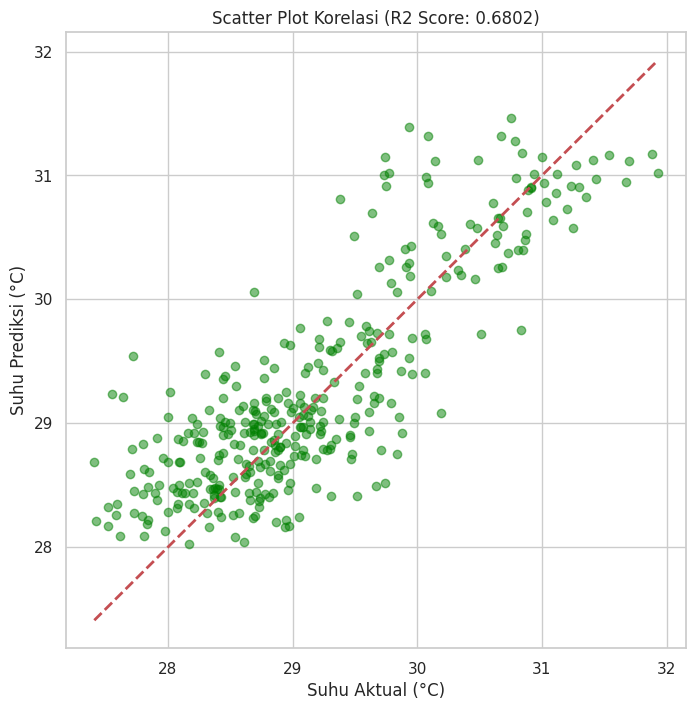

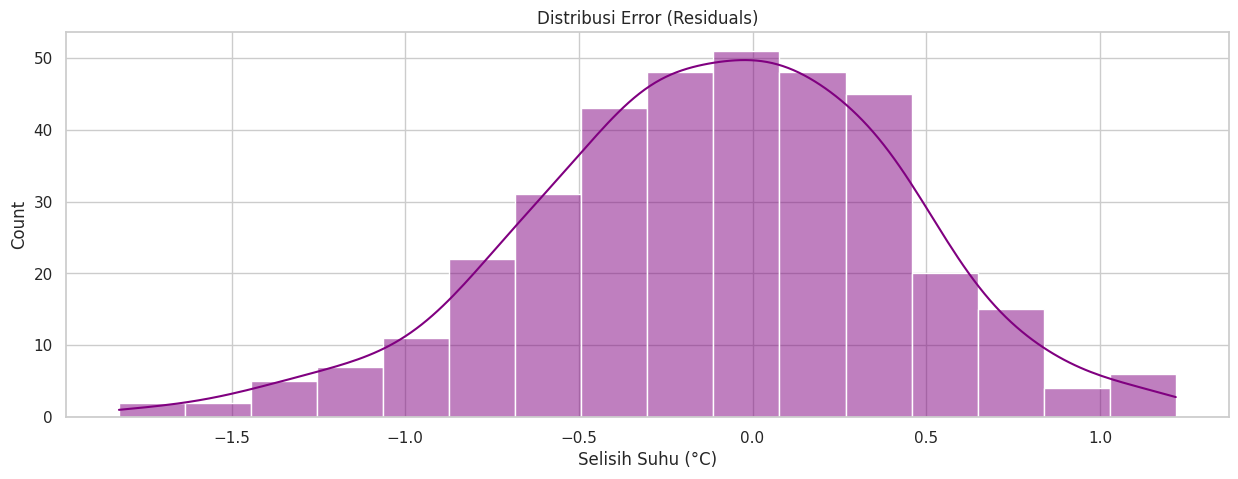

In [ ]:
# Visualisasi 3: Scatter Plot (Korelasi)
plt.figure(figsize=(8, 8))
plt.scatter(y_act, y_pred, alpha=0.5, color='green')
plt.plot([y_act.min(), y_act.max()], [y_act.min(), y_act.max()], 'r--', lw=2)
plt.xlabel('Suhu Aktual (°C)')
plt.ylabel('Suhu Prediksi (°C)')
plt.title(f'Scatter Plot Korelasi (R2 Score: {r2_score(y_act, y_pred):.4f})')
plt.show()

# Visualisasi 4: Residual (Error) Analysis
residual = y_act - y_pred
plt.figure(figsize=(15, 5))
sns.histplot(residual, kde=True, color='purple')
plt.title('Distribusi Error (Residuals)')
plt.xlabel('Selisih Suhu (°C)')
plt.show()

🔮 Menghitung peramalan dengan pola musiman...


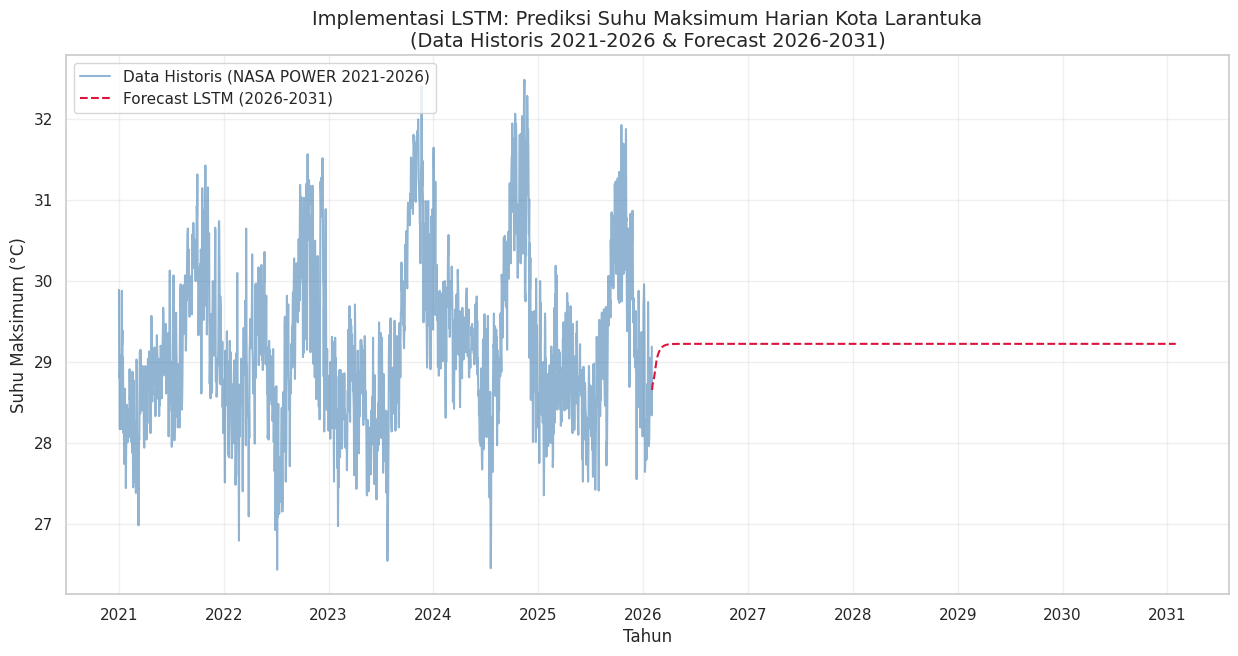

In [ ]:
# ============================================================
# PERBAIKAN: Recursive Forecasting dengan Konteks Musiman
# ============================================================
future_days = 1825
current_window = 60

# Ambil data terakhir
last_batch = scaled_data[-current_window:].reshape(1, current_window, len(features))

fc_scaled = []

# Dapatkan tanggal terakhir untuk menghitung siklus musiman
current_date = df['Date'].max()

print("🔮 Menghitung peramalan dengan pola musiman...")
for _ in range(future_days):
    current_date += pd.Timedelta(days=1)

    # 1. Prediksi suhu
    p = model.predict(last_batch, verbose=0)
    fc_scaled.append(p[0, 0])

    # 2. Siapkan baris baru (new_row)
    # Jangan isi 0! Ambil nilai terakhir dari fitur lain agar stabil
    new_row = last_batch[:, -1, :].copy().reshape(1, 1, len(features))

    # Update kolom 0 (T2M_MAX) dengan hasil prediksi
    new_row[0, 0, 0] = p[0, 0]

    # --- TIPS TAMBAHAN (Jika Anda punya fitur musiman) ---
    # Jika di training Anda menggunakan fitur bulan/hari, update di sini:
    # day_of_year = current_date.dayofyear
    # new_row[0, 0, kolom_sin_day] = np.sin(2 * np.pi * day_of_year / 365.25)
    # -----------------------------------------------------

    # 3. Update window
    last_batch = np.concatenate([last_batch[:, 1:, :], new_row], axis=1)

# Inverse scaling ke Celcius
fc_scaled = np.array(fc_scaled)
dummy = np.zeros((len(fc_scaled), len(features)))
dummy[:, 0] = fc_scaled
fc_final = scaler.inverse_transform(dummy)[:, 0]

# Buat deret tanggal masa depan (Feb 2026 - 2031)
last_date = df['Date'].max()
fc_dates = pd.date_range(last_date + pd.Timedelta(days=1), periods=future_days)

# ============================================================
# 3. Plotting Lengkap (Tampilan Persis File .py Anda)
# ============================================================
plt.figure(figsize=(15, 7))

# Plot Data Historis (Warna Biru/Gray - Mencakup 2021-2026)
plt.plot(df['Date'], df['T2M_MAX'], label='Data Historis (NASA POWER 2021-2026)', color='steelblue', alpha=0.6)

# Plot Forecast (Warna Merah Putus-putus - Mencakup 2026-2031)
plt.plot(fc_dates, fc_final, label='Forecast LSTM (2026-2031)', color='crimson', linestyle='--', linewidth=1.5)

# Pengaturan Sumbu dan Judul
plt.title('Implementasi LSTM: Prediksi Suhu Maksimum Harian Kota Larantuka\n(Data Historis 2021-2026 & Forecast 2026-2031)', fontsize=14)
plt.xlabel('Tahun')
plt.ylabel('Suhu Maksimum (°C)')

# Formatter agar tahun muncul jelas di sumbu X
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

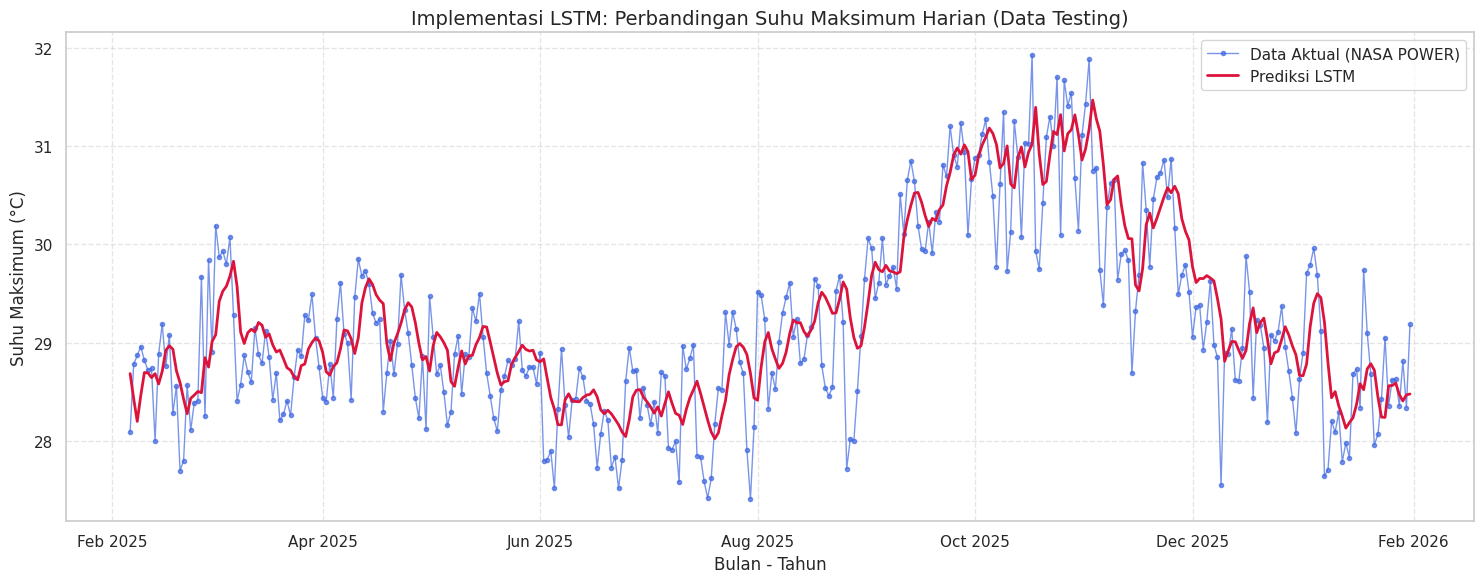

In [ ]:
# ============================================================
# CELL 11: DETAIL PERBANDINGAN DATA TESTING
# ============================================================

# Ambil tanggal khusus untuk data testing agar panjangnya SAMA (Sync)
test_dates = df['Date'].iloc[-len(y_act):].values

plt.figure(figsize=(15, 6))

# Plot Data Aktual
plt.plot(test_dates, y_act, label='Data Aktual (NASA POWER)',
         color='royalblue', marker='o', markersize=3, alpha=0.7, linewidth=1)

# Plot Data Prediksi
plt.plot(test_dates, y_pred, label='Prediksi LSTM',
         color='crimson', linewidth=2)

# Format Sumbu X agar rapi (tampilan bulan-tahun)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=0)

plt.title('Implementasi LSTM: Perbandingan Suhu Maksimum Harian (Data Testing)', fontsize=14)
plt.xlabel('Bulan - Tahun', fontsize=12)
plt.ylabel('Suhu Maksimum (°C)', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('04_prediksi_testing.png', dpi=300) # Simpan otomatis buat laporan
plt.show()

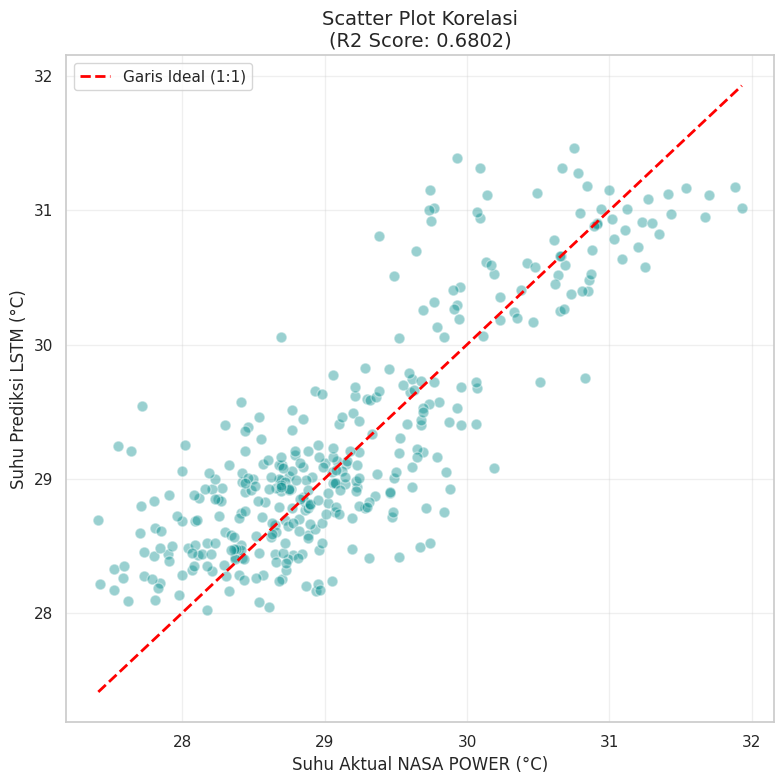


HASIL EVALUASI AKURASI MODEL
R-Squared (R2)  : 0.6802
RMSE            : 0.5387 °C
MAE             : 0.4224 °C


In [ ]:
# ============================================================
# CELL 12: SCATTER PLOT DAN METRIK AKURASI
# ============================================================

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.figure(figsize=(8, 8))

# Membuat Scatter Plot
plt.scatter(y_act, y_pred, color='darkcyan', alpha=0.4, edgecolors='w', s=60)

# Garis Diagonal Ideal (Garis bantu akurasi)
limits = [min(y_act.min(), y_pred.min()), max(y_act.max(), y_pred.max())]
plt.plot(limits, limits, color='red', linestyle='--', lw=2, label='Garis Ideal (1:1)')

# Hitung Metrik secara otomatis
r2 = r2_score(y_act, y_pred)
rmse = np.sqrt(mean_squared_error(y_act, y_pred))
mae = mean_absolute_error(y_act, y_pred)

plt.title(f'Scatter Plot Korelasi\n(R2 Score: {r2:.4f})', fontsize=14)
plt.xlabel('Suhu Aktual NASA POWER (°C)', fontsize=12)
plt.ylabel('Suhu Prediksi LSTM (°C)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('05_scatter_plot.png', dpi=300)
plt.show()

print("\n" + "="*35)
print("HASIL EVALUASI AKURASI MODEL")
print("="*35)
print(f"R-Squared (R2)  : {r2:.4f}")
print(f"RMSE            : {rmse:.4f} °C")
print(f"MAE             : {mae:.4f} °C")
print("="*35)